# Edge Agent Lab: portfolio summary

**One engineering story across three projects:** acquire and version sensor data, train compact models, investigate data incidents with evidence, and select deployable candidates under explicit constraints.

Start here, then follow [Edge Sense](01_edge_sense.ipynb), [Data Steward](02_data_steward.ipynb), and [Edge Pilot](03_edge_pilot.ipynb).

## Reading roadmap

Start with the shared sensor-data problem, then inspect the evidence index and recorded verification. Follow Edge Sense for model experiments, Data Steward for incident investigation, Edge Pilot for constrained selection, and the toolkit for pruning and quantization details. You should finish knowing which evidence supports each claim and where to reproduce it.

Read the explanations before executing each block, and run cells in order: later blocks reuse variables created earlier. Saved output is a record of an earlier execution; running a report cell reads the report files currently in your checkout.


## How to run
Run all cells from the repository root or this directory. Install the notebook extra with `uv pip install -e '.[notebooks]'` and select that Python environment. The report sections need only committed JSON measurements. They do not need checkpoints, API keys, downloads, or Apple hardware. Edge Sense and Edge Pilot also have an optional local inference section that needs generated checkpoints and validation arrays. Saved study outputs and fresh local measurements are labeled separately.

## The problem in everyday terms

Imagine a phone that needs to tell whether its owner is walking, climbing stairs, sitting, standing, or lying down. It gets streams of numbers from motion sensors, not a written description of the activity. A model learns patterns in those streams and returns one of six activity labels.

Getting a good model is only one part of the job. The recordings need to be downloaded and checked. A smaller model needs to fit the device. A broken sensor needs to be noticed. Someone also needs to explain why one model was chosen over another. These three projects implement those parts around the same dataset, so the outputs of one project are useful to the others.

## Follow one recording through the code

1. The data loader downloads the UCI archive and checks its SHA256, a fingerprint that changes if the file changes. It then saves arrays with explicit train, validation, and test splits.
2. Edge Sense takes a short window of sensor readings and predicts an activity. It compares larger and smaller networks and tests what happens when a sensor disappears.
3. Data Steward takes a request such as “investigate a missing gyroscope,” looks up the dataset and runbooks, and runs the relevant checks. Its output includes the tools it called and what each returned.
4. Edge Pilot compares candidates against a size, speed, accuracy, and sensor-outage budget. It either returns a candidate that passes every gate or reports that none fit.

The notebooks below read saved runs of this pipeline. They are useful for reviewing what happened without first spending time training the models.

## A few terms used in the results

**Inference** means running an already trained model on new input. **Training** changes its weights using labeled examples. A **checkpoint** is a file containing those weights and the network configuration.

**Macro F1** scores each activity separately and averages the six scores. A result of 1 is perfect; 0 is the bottom of the scale. This makes it harder for one frequent activity to hide weak performance on another. **Validation** data is used to make engineering choices. **Test** data is kept separate until those choices are finished.

A **seed** controls random initialization and training randomness. Repeating a run with three seeds gives a first look at how much its result varies. **p95 latency** is the duration below which 95% of measured calls finish. It is a timing summary, not an accuracy score.

## Where GPU inference fits

The original tables report CPU runs. The optional inference cells in the Edge Sense and Edge Pilot notebooks now run floating-point checkpoints on NVIDIA CUDA, Apple MPS, or CPU. They record a new measurement on the current machine and compare its predictions with a CPU reference. GPU inference does not retrain the network or change the saved study results.

For these small networks, dispatching work to a GPU can cost more than the calculation itself. Batch size 1 answers a latency question; a larger batch answers a throughput question. Neither automatically guarantees a speedup. The Data Steward notebook explains its separate llama.cpp GPU setup.

**Before you run:** Run this setup first so later cells can locate the repository, read the saved reports, and display consistent tables and plots.

**How to read the output:** This loads recorded measurements into memory; it does not train a model or rerun the original experiments. A printed SHA256 identifies the exact report bytes used.


In [1]:
from pathlib import Path
import hashlib
import json
import statistics
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reports/results.json").is_file())
RESULTS_PATH = ROOT / "reports/results.json"
r = json.loads(RESULTS_PATH.read_text())
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
def table(headers, rows):
    def cell(v):
        return str(v).replace("|", " / ").replace("\n", " ")
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n" + "\n".join("| " + " | ".join(cell(v) for v in row) + " |" for row in rows)))
print("Evidence:", RESULTS_PATH.relative_to(ROOT))
print("SHA256:", hashlib.sha256(RESULTS_PATH.read_bytes()).hexdigest())
print("This notebook reanalyzes saved measurements; it does not rerun training or download data.")

Evidence: reports/results.json
SHA256: b382e4a91a7e8103fa6ab03709309848592cd80b8a4ee3c777e6e82ce588636d
This notebook reanalyzes saved measurements; it does not rerun training or download data.


## What each project demonstrates

| Project | Engineering focus | Evidence |
|---|---|---|
| Edge Sense | Multichannel ML, compression, simulation-to-real, Core ML and Swift | Three-seed held-out comparisons, real negative transfer result, export parity |
| Data Steward | Retrieval, typed tools, data catalog, provenance, local intent routing | Eight-case strict regression suite, successful and failed tool traces |
| Edge Pilot | Bounded search, validation-only gates, monitoring | Measured candidates, explicit infeasibility, labeled outage replay |

The shared pipeline pins source checksums, separates subjects and selection data, records experiments, and preserves machine-readable evidence. See [architecture](../docs/ARCHITECTURE.md) and [role alignment](../docs/ROLE_ALIGNMENT.md).

**Before you run:** Read this as an evidence index across projects, rather than one combined benchmark. The cell extracts saved quality, storage, routing, and selection results.

**How to read the output:** Higher macro F1 indicates better classification; a larger reduction factor means less stored model state. Router success counts apply to the curated incident suite. These quantities answer different questions and should not be ranked against one another.


| Evidence | Recorded result |
| --- | --- |
| Teacher test macro F1 (three-seed mean) | 0.9280 |
| Distilled student test macro F1 (three-seed mean) | 0.9234 |
| Supervised student serialized-state reduction | 8.10× |
| Intent router strict regression success | 8/8 |
| On-demand search winner | width-6-base |
| Selected search-model state | 21,402 bytes |
| Infeasible storage probe | no_feasible_candidate |

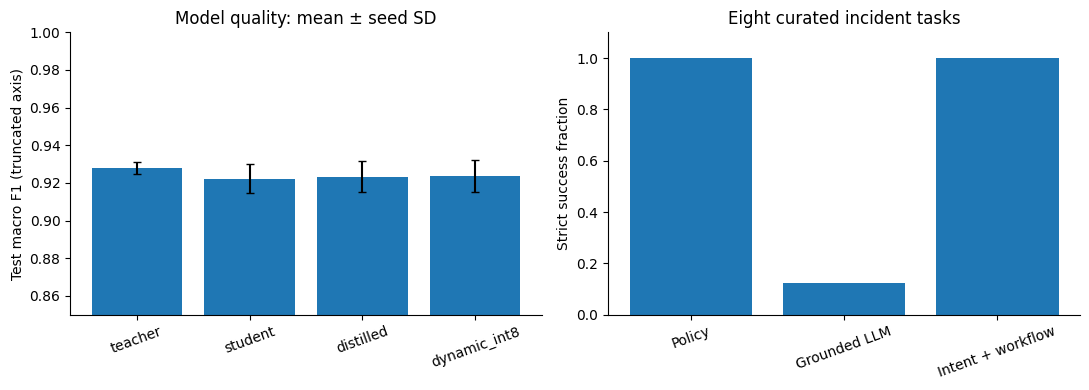

In [2]:
a = {x["name"]: x for x in r["aggregates"]}
w = r["search"]["winner"]
table(["Evidence", "Recorded result"], [
    ("Teacher test macro F1 (three-seed mean)", f'{a["teacher"]["test_f1_mean"]:.4f}'),
    ("Distilled student test macro F1 (three-seed mean)", f'{a["distilled"]["test_f1_mean"]:.4f}'),
    ("Supervised student serialized-state reduction", f'{a["teacher"]["bytes"]/a["student"]["bytes"]:.2f}×'),
    ("Intent router strict regression success", f'{sum(x["passed"] for x in r["llm_intent"]["results"])}/{r["llm_intent"]["cases"]}'),
    ("On-demand search winner", w["candidate"]),
    ("Selected search-model state", f'{w["benchmark"]["state_dict_bytes"]:,} bytes'),
    ("Infeasible storage probe", r["infeasible_pilot"]["status"]),
])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
names = ["teacher", "student", "distilled", "dynamic_int8"]
axes[0].bar(names, [a[k]["test_f1_mean"] for k in names], yerr=[a[k]["test_f1_std"] for k in names], capsize=3)
axes[0].set(ylim=(.85, 1), ylabel="Test macro F1 (truncated axis)", title="Model quality: mean ± seed SD")
axes[0].tick_params(axis="x", rotation=20)
keys = ["steward", "llm_grounded", "llm_intent"]
axes[1].bar(["Policy", "Grounded LLM", "Intent + workflow"], [r[k]["task_success_rate"] for k in keys])
axes[1].set(ylim=(0, 1.1), ylabel="Strict success fraction", title="Eight curated incident tasks")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## Findings worth discussing
- Compact students preserve much of the teacher quality with smaller serialized state. Model size, latency, and runtime memory remain different quantities.
- Synthetic pretraining under the equal-label budget did not improve held-out macro F1. Independent-dataset transfer is limited by substantial domain mismatch.
- Relevant retrieval and valid JSON do not ensure correct tool execution. Intent classification plus typed execution passes the curated suite; that is narrower than general autonomous planning.
- Constraint handling includes an explicit no-feasible-candidate outcome. The optimization workflow uses validation data, and its telemetry is a labeled replay with synthetic faults.

These results are measured engineering evidence, with small evaluation suites and machine-specific timing. They do not establish production readiness or general superiority.

**Before you run:** Check which verification was recorded when the study was produced, then inspect the saved selection boundaries.

**How to read the output:** The table reports historical check status. The assertions confirm that the saved report excludes test-based selection and represents infeasibility with no winner. Passing these assertions is not a fresh unit-test run.


In [3]:
verification = json.loads((ROOT / "reports/verification.json").read_text())
# This is the original saved study verification, not a fresh test invocation.
table(["Original verification", "Saved status"], [(k, verification[k]) for k in ["unit_tests_passed", "lint", "format", "dependency_lock", "native_student_parity", "native_search_parity"]])
assert r["test"]["used_for_selection"] is False
assert r["search"]["test_metrics_used"] is False
assert r["infeasible_pilot"]["winner"] is None
print("Summary evidence invariants passed.")

| Original verification | Saved status |
| --- | --- |
| unit_tests_passed | 40 |
| lint | passed |
| format | passed |
| dependency_lock | passed |
| native_student_parity | True |
| native_search_parity | True |

Summary evidence invariants passed.


## Review and reproduce
Read the three project notebooks for tables, plots, trace inspection, and limitations. The notebook outputs are regenerated from committed `reports/results.json`; they do not pretend to retrain models. To reproduce experiments, use the [full reproduction guide](../docs/REPRODUCING.md). For attribution and dataset handling, read the [data card](../docs/DATA_CARD.md) and [sources](../docs/SOURCES.md).

Original results are also available in [the measured report](../reports/RESULTS.md) and [offline dashboard](../reports/index.html).

## Pruning an already trained network

The earlier comparisons use distillation and quantization. **Distillation** changes how a smaller network learns from a teacher. **Quantization** stores or computes selected weights using fewer bits. **Pruning** removes connections or channels from a network that already has trained weights. These methods solve related problems, but they are different operations.

The added experiment starts from the same seed-7 floating distilled student for every candidate. It compares the original model, a dense model with extra fine-tuning, two magnitude-pruned models, and two physically smaller channel-pruned models. The extra dense run is a control: otherwise an apparent pruning benefit could simply come from giving a model more training.

Results below come from `reports/pruning.json`, separate from the original three-seed study. This added comparison uses one checkpoint and one fine-tuning seed.

**Before you run:** Load the pruning report before comparing candidates. All candidates should trace back to the recorded source checkpoint, so differences have a common starting point.

**How to read the output:** The checkpoint fingerprint and selection rule describe experiment provenance. The assertion checks the saved claim that test data was excluded from selection; it does not rerun training.


In [4]:
pruning = json.loads((ROOT / "reports/pruning.json").read_text())
pruned = {c["name"]: c for c in pruning["candidates"]}
print("Source checkpoint SHA256:", pruning["source_sha256"])
print("Fine-tuning seed:", pruning["seed"], "| maximum epochs:", pruning["fine_tuning_epochs"])
print("Selection:", pruning["selection_rule"])
assert pruning["test_used_for_selection"] is False

Source checkpoint SHA256: d207e077aa5751f87c518590e3afdc8e680bd71220900ee687217bbe61c1f0ab
Fine-tuning seed: 7 | maximum epochs: 5
Selection: smallest state within 0.02 validation macro F1 of original dense source


**Before you run:** Compare what each optimization changes before reading its storage result. This cell contrasts learning methods, lower precision, zero weights, and physical channel removal.

**How to read the output:** The half-width comparison uses checkpoint bytes. Zeros inside a dense tensor need not reduce its stored dimensions or runtime; the separate deployment notebook compares a different archive format.


In [5]:
table(["Method", "What changes", "Measured in this project"], [
    ("Distillation", "Student learns from teacher scores", "Original three-seed comparison"),
    ("Quantization", "Selected weights use fewer bits", "Dynamic INT8 and Core ML weight compression"),
    ("Magnitude pruning", "Small weights become zero; shapes stay the same", "50% / 70% weight sparsity with masked fine-tuning"),
    ("Channel pruning", "Layers lose channels and dense dimensions shrink", "75%-width / 50%-width compact models"),
])
base, small = pruned["dense_original"], pruned["channels_50pct"]
print(f"Half-width: {base['checkpoint_bytes']:,} → {small['checkpoint_bytes']:,} checkpoint bytes")
print(f"Held-out macro F1: {base['test']['macro_f1']:.4f} → {small['test']['macro_f1']:.4f}")
print("Magnitude pruning retains the original dense checkpoint size:", pruned["magnitude_50"]["checkpoint_bytes"] == base["checkpoint_bytes"])

| Method | What changes | Measured in this project |
| --- | --- | --- |
| Distillation | Student learns from teacher scores | Original three-seed comparison |
| Quantization | Selected weights use fewer bits | Dynamic INT8 and Core ML weight compression |
| Magnitude pruning | Small weights become zero; shapes stay the same | 50% / 70% weight sparsity with masked fine-tuning |
| Channel pruning | Layers lose channels and dense dimensions shrink | 75%-width / 50%-width compact models |

Half-width: 61,034 → 21,290 checkpoint bytes
Held-out macro F1: 0.9139 → 0.8969
Magnitude pruning retains the original dense checkpoint size: True


The channel-pruned model saves space at an accuracy cost. Magnitude pruning demonstrates sparsity, but the dense execution path does not turn those zeros into a smaller stored network. The [Edge Sense notebook](01_edge_sense.ipynb) includes before/after fine-tuning results and repeated CPU/GPU timings. The [Edge Pilot notebook](03_edge_pilot.ipynb) recomputes the pruning selection gate. [Code and run instructions](../docs/PRUNING.md).

## Pruning and quantization toolkit

The [dedicated optimization notebook](04_post_training_toolkit.ipynb) collects magnitude pruning, physical channel removal, dynamic INT8, calibrated static INT8 for both convolution and linear layers, QAT, and pruning + quantization. It includes runnable examples, export/load checks, measured size and timing comparisons, and CPU/GPU runtime limits. QAT and pruning recovery are labeled fine-tuning steps; PTQ itself does not train weights.